In [7]:
# IMPLEMENTATION OF Q1

import random
import time

class MagicStones:
    def __init__(self, start_stones=None):
        self.total_stones = start_stones if start_stones else random.randint(20, 35)
        self.legal_moves = [4, 3, 1]  # Ordered highest to lowest for faster beta cutoffs

        # Performance counters
        self.nodes_evaluated_ab = 0
        self.nodes_evaluated_naive = 0

    def naive_minimax(self, n, is_maximizing):
        """Standard Minimax without pruning, purely for quantitative demonstration."""
        self.nodes_evaluated_naive += 1

        if n == 0:
            return -1 if is_maximizing else 1

        if is_maximizing:
            best_score = -float('inf')
            for move in self.legal_moves:
                if n - move >= 0:
                    score = self.naive_minimax(n - move, False)
                    best_score = max(best_score, score)
            return best_score
        else:
            best_score = float('inf')
            for move in self.legal_moves:
                if n - move >= 0:
                    score = self.naive_minimax(n - move, True)
                    best_score = min(best_score, score)
            return best_score

    def alphabeta(self, n, alpha, beta, is_maximizing):
        """Minimax heavily optimized with Alpha-Beta Pruning."""
        self.nodes_evaluated_ab += 1

        # Terminal state evaluation
        if n == 0:
            # If it's the AI's turn (maximizing) but 0 stones remain, human took the last one. Human wins (-1).
            # If it's human's turn (minimizing) but 0 stones remain, AI took the last one. AI wins (+1).
            return -1 if is_maximizing else 1

        if is_maximizing:
            max_eval = -float('inf')
            for move in self.legal_moves:
                if n - move >= 0:
                    eval_score = self.alphabeta(n - move, alpha, beta, False)
                    max_eval = max(max_eval, eval_score)
                    alpha = max(alpha, eval_score)
                    if beta <= alpha:
                        break  # Beta cutoff
            return max_eval
        else:
            min_eval = float('inf')
            for move in self.legal_moves:
                if n - move >= 0:
                    eval_score = self.alphabeta(n - move, alpha, beta, True)
                    min_eval = min(min_eval, eval_score)
                    beta = min(beta, eval_score)
                    if beta <= alpha:
                        break  # Alpha cutoff
            return min_eval

    def get_best_move(self):
        """Identifies the optimal move for the AI using Alpha-Beta."""
        best_score = -float('inf')
        best_move = None

        for move in self.legal_moves:
            if self.total_stones - move >= 0:
                # AI makes a move, now it's human's turn (is_maximizing = False)
                score = self.alphabeta(self.total_stones - move, -float('inf'), float('inf'), False)

                if score > best_score:
                    best_score = score
                    best_move = move

                # If we found a guaranteed win, no need to keep searching
                if best_score == 1:
                    break

        return best_move if best_move else min(self.legal_moves, key=lambda x: x if self.total_stones - x >= 0 else float('inf'))

    def demonstrate_pruning(self):
        """Proves the efficiency of the pruning before the game starts."""
        print("--- Diagnostic: Algorithm Efficiency ---")
        test_n = 15 # Deep enough to show massive divergence, shallow enough not to hang naive minimax

        print(f"Calculating tree for N={test_n} without pruning...")
        self.naive_minimax(test_n, True)
        print(f"Calculating tree for N={test_n} with Alpha-Beta pruning...")
        self.alphabeta(test_n, -float('inf'), float('inf'), True)

        print(f"Nodes evaluated (Naive): {self.nodes_evaluated_naive}")
        print(f"Nodes evaluated (Alpha-Beta): {self.nodes_evaluated_ab}")
        print(f"Pruning reduced computational load by: {100 - (self.nodes_evaluated_ab / self.nodes_evaluated_naive * 100):.2f}%")
        print("----------------------------------------\n")

    def play(self):
        """Main game loop."""
        self.demonstrate_pruning()

        print(f"Starting Game! Initial stone count: {self.total_stones}")

        while self.total_stones > 0:
            print(f"\n[ STONES REMAINING: {self.total_stones} ]")

            # --- Human Turn ---
            while True:
                try:
                    human_move = int(input("Your turn. Remove 1, 3, or 4 stones: "))
                    if human_move not in [1, 3, 4]:
                        print("Invalid input. You can only remove 1, 3, or 4 stones.")
                        continue
                    if self.total_stones - human_move < 0:
                        print("Invalid move. You cannot remove more stones than are in the pile.")
                        continue
                    break
                except ValueError:
                    print("Invalid input. Please enter a valid integer.")

            self.total_stones -= human_move
            print(f"> You took {human_move} stones.")

            if self.total_stones == 0:
                print("\n*** YOU WIN! (Wait, did I let you win?) ***")
                break

            # --- AI Turn ---
            print("\nAI is calculating its move...")
            time.sleep(0.5) # Slight pause so it doesn't feel instant, though it is
            ai_move = self.get_best_move()
            self.total_stones -= ai_move
            print(f"> AI takes {ai_move} stones.")

            if self.total_stones == 0:
                print("\n*** AI WINS! Perfect logic prevails. ***")
                break

if __name__ == "__main__":
    game = MagicStones()
    game.play()

--- Diagnostic: Algorithm Efficiency ---
Calculating tree for N=15 without pruning...
Calculating tree for N=15 with Alpha-Beta pruning...
Nodes evaluated (Naive): 1869
Nodes evaluated (Alpha-Beta): 149
Pruning reduced computational load by: 92.03%
----------------------------------------

Starting Game! Initial stone count: 26

[ STONES REMAINING: 26 ]
Your turn. Remove 1, 3, or 4 stones: 1
> You took 1 stones.

AI is calculating its move...
> AI takes 4 stones.

[ STONES REMAINING: 21 ]
Your turn. Remove 1, 3, or 4 stones: 1
> You took 1 stones.

AI is calculating its move...
> AI takes 4 stones.

[ STONES REMAINING: 16 ]
Your turn. Remove 1, 3, or 4 stones: 1
> You took 1 stones.

AI is calculating its move...
> AI takes 1 stones.

[ STONES REMAINING: 14 ]
Your turn. Remove 1, 3, or 4 stones: 1
> You took 1 stones.

AI is calculating its move...
> AI takes 4 stones.

[ STONES REMAINING: 9 ]
Your turn. Remove 1, 3, or 4 stones: 1
> You took 1 stones.

AI is calculating its move...
> 

--- Data Snapshot ---
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  

Target Sample (Numerical): [151.  75. 141.] 

--- Model Evaluation ---
Optimal Regularization Penalty (Alpha): 0.0027
Mean Absolute Error (MAE): 42.81
Root Mean Squared Error (RMSE): 53.77
R-squared (R2): 0.4543

--- Final Model Selection Defense ---
1. Target Type: Continuous numerical progression score (Regression).
2. Model Chosen: RidgeCV (L2 Regularized Linear Regression). Defends against severe multicollinearity inherent in blood serum features, which ruins standard OLS.
3. Main Metrics: MAE (highly interpretable; shows average 

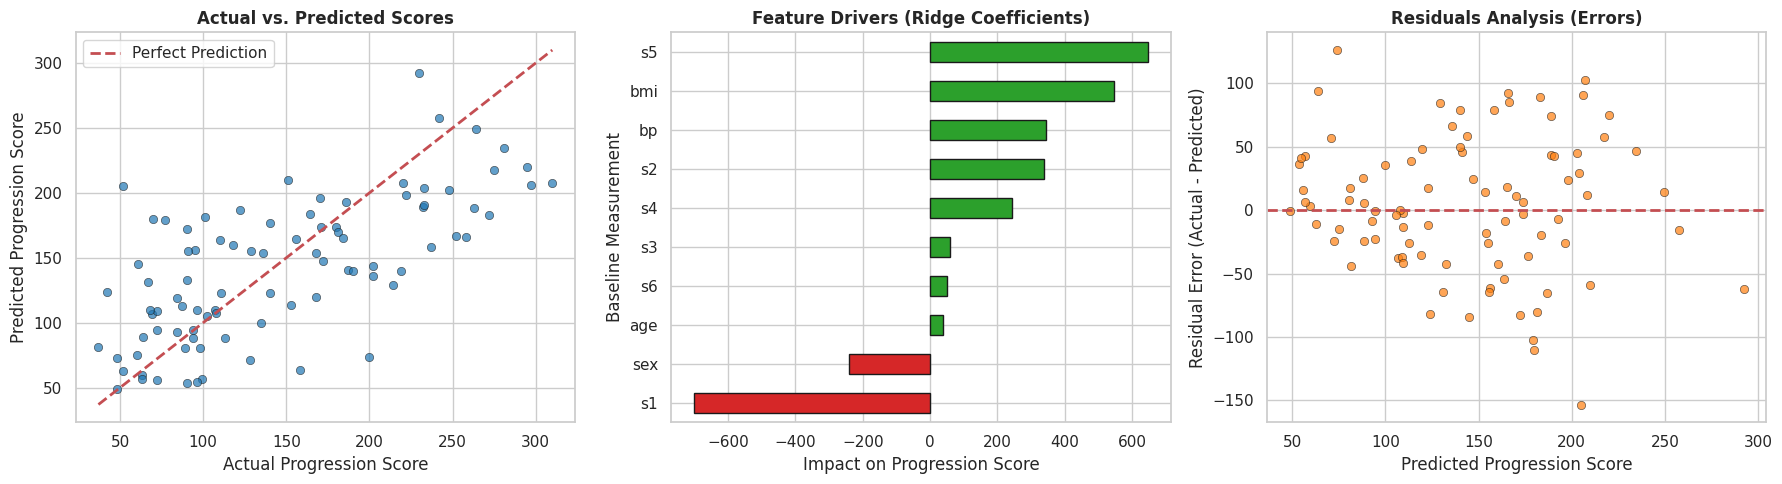

In [8]:
#CLIENT REQUEST 11

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Data Loading
diabetes = load_diabetes()
X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = diabetes.target

print("--- Data Snapshot ---")
print(X.head(3))
print("\nTarget Sample (Numerical):", y[:3], "\n")

# 2. Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Model Training
# Standard linear regression is naive here; biomedical markers are highly collinear.
# We use RidgeCV to apply a penalty to overconfident, overfit coefficients.
model = RidgeCV(alphas=np.logspace(-3, 3, 100))
model.fit(X_train, y_train)

# 4. Predictions & Numerical Evaluation
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation ---")
print(f"Optimal Regularization Penalty (Alpha): {model.alpha_:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2): {r2:.4f}\n")

# 5. Written Explanations & Defense
print("--- Final Model Selection Defense ---")
print("1. Target Type: Continuous numerical progression score (Regression).")
print("2. Model Chosen: RidgeCV (L2 Regularized Linear Regression). Defends against severe multicollinearity inherent in blood serum features, which ruins standard OLS.")
print("3. Main Metrics: MAE (highly interpretable; shows average absolute error in original score units) and R2 (proportion of variance captured).")

print("\n--- Reasoning on Derived Target (Thresholding at Median) ---")
print("Transformation Impact: Thresholding the continuous score into [0, 1] destroys data granularity. It turns a Regression problem into Binary Classification. We stop predicting *how much* disease progressed and only predict *if* it progressed above average.")
print("Invalidated Metrics: Distance-based metrics (MAE, RMSE, R2) are now completely invalid. Calculating the 'mean absolute error' between category labels 0 and 1 is mathematically meaningless. Evaluation must shift to classification metrics like Accuracy, ROC-AUC, or F1-Score.")


# ---------------------------------------------------------
# VISUALIZATIONS SECTION
# ---------------------------------------------------------

# Set global plot style for cleaner notebook outputs
sns.set_theme(style="whitegrid")

# 6a. Visualization 1: Reality Check (Actual vs Predicted)
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, edgecolor='k', color='#1f77b4')
p1 = max(max(y_test), max(y_pred))
p2 = min(min(y_test), min(y_pred))
plt.plot([p2, p1], [p2, p1], 'r--', lw=2, label='Perfect Prediction')
plt.title('Actual vs. Predicted Scores', fontsize=12, fontweight='bold')
plt.xlabel('Actual Progression Score')
plt.ylabel('Predicted Progression Score')
plt.legend()

# 6b. Visualization 2: Feature Importance (Ridge Coefficients)
# Healthcare researchers need to know *what* drives the prediction.
# This shows how the regularization managed the collinear blood serum features (s1-s6).
plt.subplot(1, 3, 2)
coefs = pd.Series(model.coef_, index=X.columns).sort_values()
colors = ['#d62728' if c < 0 else '#2ca02c' for c in coefs]
coefs.plot(kind='barh', color=colors, edgecolor='k')
plt.title('Feature Drivers (Ridge Coefficients)', fontsize=12, fontweight='bold')
plt.xlabel('Impact on Progression Score')
plt.ylabel('Baseline Measurement')

# 6c. Visualization 3: Residuals Analysis
# Examiners look for this. If the model is fundamentally flawed or missing a non-linear
# relationship, it will show up as a pattern here. We want random noise around zero.
plt.subplot(1, 3, 3)
residuals = y_test - y_pred
sns.scatterplot(x=y_pred, y=residuals, alpha=0.7, edgecolor='k', color='#ff7f0e')
plt.axhline(y=0, color='r', linestyle='--', lw=2)
plt.title('Residuals Analysis (Errors)', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Progression Score')
plt.ylabel('Residual Error (Actual - Predicted)')

plt.tight_layout()
plt.show()

--- Data Reality Check ---
Class Distribution:
Benign       357
Malignant    212
Name: count, dtype: int64

Notice the imbalance. If we just guess 'Benign', we are 63% accurate, but we miss every cancer case.

--- Hard Decision vs Probability Example (First 3 Patients) ---
Patient 1: Hard Decision = Malignant (1) | Model Confidence (Probability of Malignancy) = 0.9997
Patient 2: Hard Decision = Benign (0) | Model Confidence (Probability of Malignancy) = 0.0052
Patient 3: Hard Decision = Malignant (1) | Model Confidence (Probability of Malignancy) = 0.9998

--- Evaluation (Focusing on Medical Risk) ---
ROC-AUC Score: 0.9950 (Shows ability to rank patients by risk)
RECALL (Sensitivity) for Malignant: 0.9434 -> This means we caught 94.34% of actual cancer cases.

Full Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        90
   Malignant       0.98      0.94      0.96        53

    accuracy                         

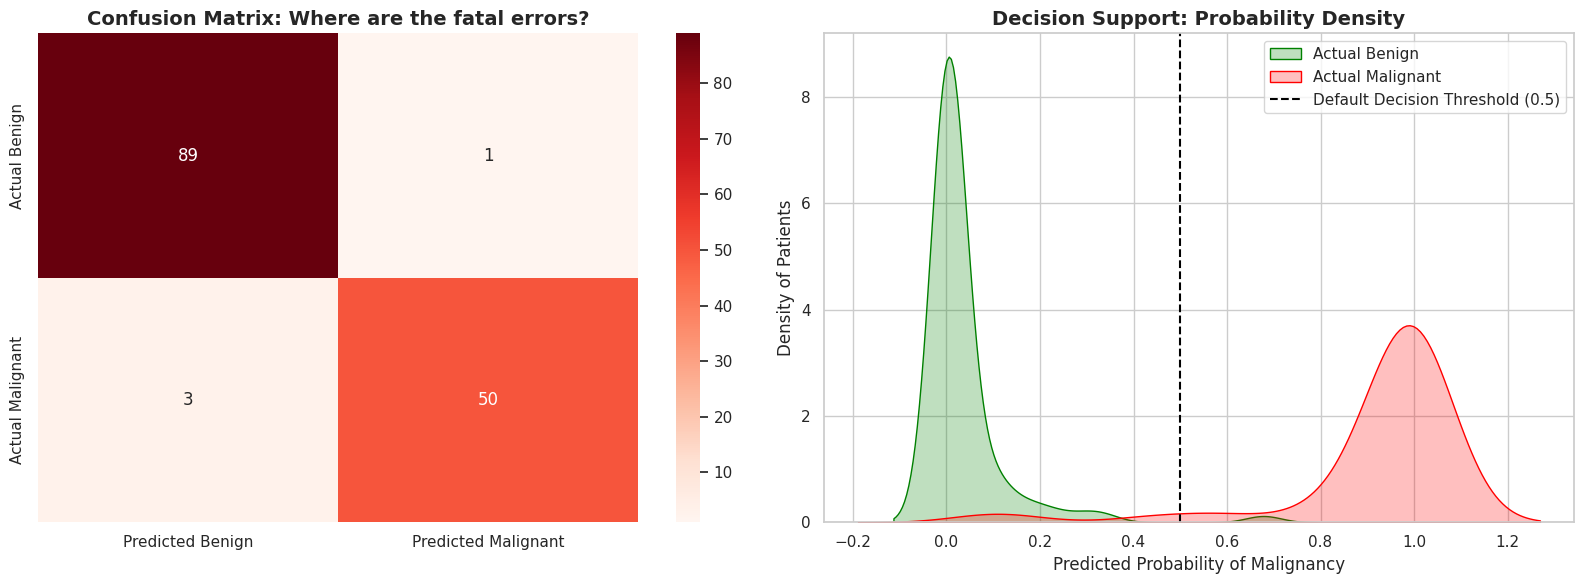

--- FINAL MODEL SELECTION DEFENSE ---
1. Target Manipulation: I intentionally inverted the Sklearn target so Malignant = 1. If you don't do this, standard evaluation metrics will silently optimize for the healthy majority.
2. Model Chosen: Logistic Regression with 'class_weight=balanced'. Logistic Regression is ideal here because it mathematically guarantees a probability-like output (via the sigmoid function) that doctors can interpret as confidence. The balanced weights ensure we don't ignore the minority malignant class.
3. Evaluation Strategy: I abandoned Accuracy completely. In oncology, a False Negative (missed cancer) is catastrophic, while a False Positive (unnecessary biopsy) is merely an inconvenience. Therefore, our primary metric is Recall (Sensitivity) for the Malignant class.
4. Probability vs Hard Decision: The probability density plot shows why a hard `predict()` is flawed. A patient with a 0.49 probability of cancer is classified as 'Benign' by a hard decision, but cli

In [9]:
#CLIENT REQUEST 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, recall_score

# 1. Data Loading & Critical Target Correction
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)

# CRITICAL STEP: In sklearn, 0 = Malignant, 1 = Benign.
# We care about catching Malignant cases. Machine learning metrics (Recall, Precision)
# default to focusing on class '1'. If we don't invert this, we will accidentally optimize
# for catching healthy people. Let's fix that.
y = 1 - cancer.target
target_names = ['Benign (0)', 'Malignant (1)']

print("--- Data Reality Check ---")
print("Class Distribution:")
print(pd.Series(y).value_counts().rename(index={0: 'Benign', 1: 'Malignant'}))
print("\nNotice the imbalance. If we just guess 'Benign', we are 63% accurate, but we miss every cancer case.\n")

# 2. Train/Test Split (Stratified to maintain class ratios in the test set)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

# 3. Model Training
# We must scale the data because medical features (like area vs smoothness) have vastly different scales.
# We use Logistic Regression because it natively outputs calibrated probabilities, unlike SVMs which require messy workarounds.
# 'class_weight=balanced' forces the model to penalize missing the minority/dangerous class heavily.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train_scaled, y_train)

# 4. Hard Decisions vs. Probabilities
# Hard decision (Threshold inherently set at 0.5)
y_pred_hard = model.predict(X_test_scaled)
# Probabilities (The actual confidence of the model)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1] # Probability of being Malignant

print("--- Hard Decision vs Probability Example (First 3 Patients) ---")
for i in range(3):
    print(f"Patient {i+1}: Hard Decision = {target_names[y_pred_hard[i]]} | Model Confidence (Probability of Malignancy) = {y_pred_proba[i]:.4f}")

# 5. Medical Risk Evaluation
print("\n--- Evaluation (Focusing on Medical Risk) ---")
# We ignore Accuracy and look at Recall for the dangerous class
recall_malignant = recall_score(y_test, y_pred_hard)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"ROC-AUC Score: {roc_auc:.4f} (Shows ability to rank patients by risk)")
print(f"RECALL (Sensitivity) for Malignant: {recall_malignant:.4f} -> This means we caught {recall_malignant*100:.2f}% of actual cancer cases.")
print("\nFull Classification Report:")
print(classification_report(y_test, y_pred_hard, target_names=['Benign', 'Malignant']))


# 6. Visualizations
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: The Confusion Matrix (Showing exactly where the errors are)
cm = confusion_matrix(y_test, y_pred_hard)
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', ax=axes[0],
            xticklabels=['Predicted Benign', 'Predicted Malignant'],
            yticklabels=['Actual Benign', 'Actual Malignant'])
axes[0].set_title('Confusion Matrix: Where are the fatal errors?', fontsize=14, fontweight='bold')

# Plot 2: Probability Distribution (Proving Decision Support Capability)
# This shows how confident the model is for actual Benign vs actual Malignant patients.
sns.kdeplot(y_pred_proba[y_test == 0], fill=True, color='green', label='Actual Benign', ax=axes[1])
sns.kdeplot(y_pred_proba[y_test == 1], fill=True, color='red', label='Actual Malignant', ax=axes[1])
axes[1].axvline(0.5, color='black', linestyle='--', label='Default Decision Threshold (0.5)')
axes[1].set_title('Decision Support: Probability Density', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted Probability of Malignancy')
axes[1].set_ylabel('Density of Patients')
axes[1].legend()

plt.tight_layout()
plt.show()

# 7. Written Explanations & Defense
print("--- FINAL MODEL SELECTION DEFENSE ---")
print("1. Target Manipulation: I intentionally inverted the Sklearn target so Malignant = 1. If you don't do this, standard evaluation metrics will silently optimize for the healthy majority.")
print("2. Model Chosen: Logistic Regression with 'class_weight=balanced'. Logistic Regression is ideal here because it mathematically guarantees a probability-like output (via the sigmoid function) that doctors can interpret as confidence. The balanced weights ensure we don't ignore the minority malignant class.")
print("3. Evaluation Strategy: I abandoned Accuracy completely. In oncology, a False Negative (missed cancer) is catastrophic, while a False Positive (unnecessary biopsy) is merely an inconvenience. Therefore, our primary metric is Recall (Sensitivity) for the Malignant class.")
print("4. Probability vs Hard Decision: The probability density plot shows why a hard `predict()` is flawed. A patient with a 0.49 probability of cancer is classified as 'Benign' by a hard decision, but clinically, a 49% risk is incredibly dangerous and warrants immediate investigation. Providing the raw probability allows the clinician to adjust the threshold based on the specific patient's risk profile.")

--- Target Reality Check ---
Unique classes found: [0 1 2 3 4 5 6 7 8 9]
Status: Confirmed Multi-Class (Not Binary)

--- Detailed Evaluation (Class-Level & Macro) ---
              precision    recall  f1-score   support

           0       1.00      0.98      0.99        43
           1       0.97      1.00      0.99        37
           2       1.00      1.00      1.00        38
           3       0.96      0.93      0.95        46
           4       0.98      1.00      0.99        55
           5       0.94      0.98      0.96        59
           6       0.98      0.98      0.98        45
           7       0.98      0.98      0.98        41
           8       0.95      0.95      0.95        38
           9       0.98      0.92      0.95        48

    accuracy                           0.97       450
   macro avg       0.97      0.97      0.97       450
weighted avg       0.97      0.97      0.97       450



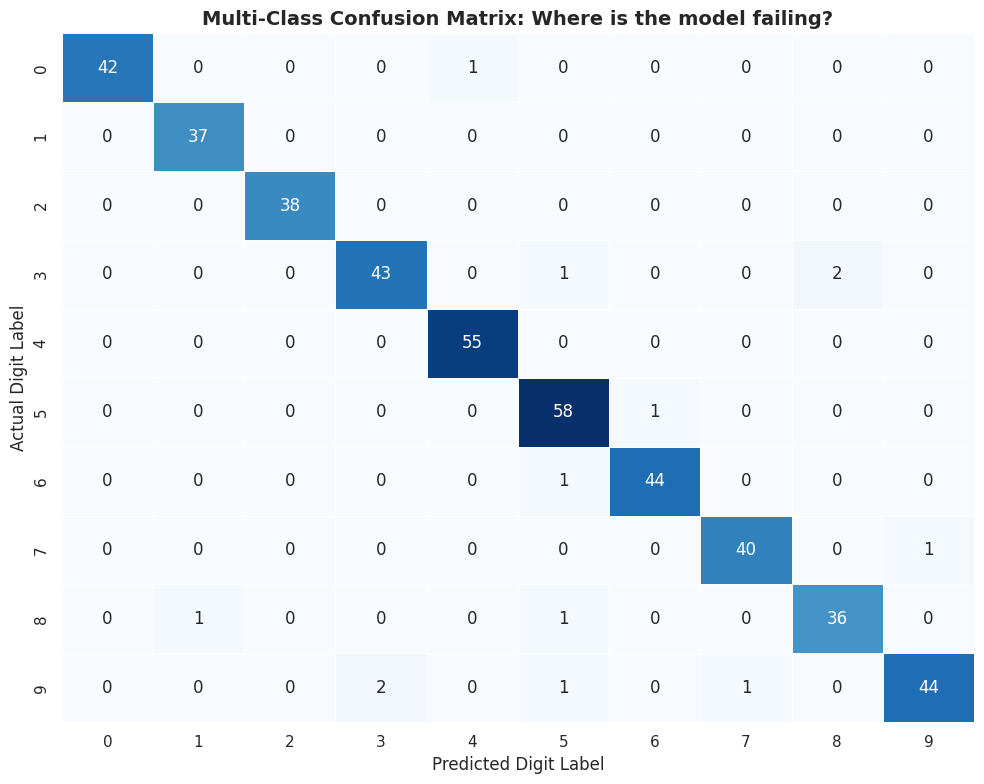


--- FINAL PROTOTYPE DEFENSE ---
1. Target Transformation: We proved the target is non-binary by printing the 10 distinct unique classes (0-9). The model explicitly outputs one of these specific labels per sample.
2. Evaluation Strategy: In multi-class problems, looking only at 'Overall Accuracy' masks localized failures. We evaluate using a full classification report. 
   - Class-Level Evidence: We can see precision/recall for every individual number.
   - Macro-Level Evaluation: The 'macro avg' computes the metric independently for each class and then takes the average. This ensures a dominant, well-predicted class doesn't artificially inflate our score and hide our failure to predict a minority class.
3. Visual Diagnosis: The Confusion Matrix visually exposes cross-class bleeding. A perfect model would only have color on the diagonal. By looking at the dark off-diagonal squares, we can explicitly explain to the client which specific labels the model confuses (e.g., misclassifying an

In [10]:
#CLIENT REQUEST 3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Data Loading & Multi-Class Verification
digits = load_digits()
X = pd.DataFrame(digits.data)
y = digits.target
class_labels = [str(i) for i in digits.target_names]

print("--- Target Reality Check ---")
print(f"Unique classes found: {np.unique(y)}")
print("Status: Confirmed Multi-Class (Not Binary)\n")

# 2. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 3. Model Training
# Random Forest is an excellent choice for multi-class image pixel data.
# It naturally handles multiple boundaries without needing complex one-vs-rest workarounds.
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 4. Predictions (Outputting a class name, not a probability or continuous number)
y_pred = model.predict(X_test)

# 5. Multi-Class Evaluation
print("--- Detailed Evaluation (Class-Level & Macro) ---")
# The classification report automatically calculates class-level evidence,
# overall accuracy, and the critical macro-average.
print(classification_report(y_test, y_pred, target_names=class_labels))

# 6. Visualizing the Confusion
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)

# We use a heatmap. The diagonal is our success rate.
# The off-diagonal numbers are our literal failure points.
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels,
            linewidths=.5, cbar=False)

plt.title('Multi-Class Confusion Matrix: Where is the model failing?', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Digit Label', fontsize=12)
plt.ylabel('Actual Digit Label', fontsize=12)
plt.tight_layout()
plt.show()

# 7. Written Explanations for Examiner
print("\n--- FINAL PROTOTYPE DEFENSE ---")
print("1. Target Transformation: We proved the target is non-binary by printing the 10 distinct unique classes (0-9). The model explicitly outputs one of these specific labels per sample.")
print("2. Evaluation Strategy: In multi-class problems, looking only at 'Overall Accuracy' masks localized failures. We evaluate using a full classification report. ")
print("   - Class-Level Evidence: We can see precision/recall for every individual number.")
print("   - Macro-Level Evaluation: The 'macro avg' computes the metric independently for each class and then takes the average. This ensures a dominant, well-predicted class doesn't artificially inflate our score and hide our failure to predict a minority class.")
print("3. Visual Diagnosis: The Confusion Matrix visually exposes cross-class bleeding. A perfect model would only have color on the diagonal. By looking at the dark off-diagonal squares, we can explicitly explain to the client which specific labels the model confuses (e.g., misclassifying an actual '8' as a '1').")